In [34]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

ds = xr.open_dataset("/scratch/nn411/clm_test/raw/uo_vo_raw_2025-12-31_2026-01-01.nc")
print(ds)
print("\ntimes:", ds.time.values)
print(f"lon: {float(ds.longitude.min()):.2f} to {float(ds.longitude.max()):.2f}")
print(f"lat: {float(ds.latitude.min()):.2f} to {float(ds.latitude.max()):.2f}")
print(f"depth levels: {ds.sizes['elevation']}  ({float(ds.elevation.min()):.0f} to {float(ds.elevation.max()):.1f} m)")
for v in ["uo", "vo"]:
    print(f"{v}: {float(ds[v].min()):.2f} to {float(ds[v].max()):.2f} m/s")

FIGS = "/home/nn411/Projects/OceanAtm/Moana-2.0/Figures"

<xarray.Dataset> Size: 157MB
Dimensions:    (time: 5, elevation: 50, latitude: 263, longitude: 299)
Coordinates:
  * time       (time) datetime64[ns] 40B 2025-12-31 ... 2026-01-01
  * elevation  (elevation) float32 200B -5.728e+03 -5.275e+03 ... -1.541 -0.494
  * latitude   (latitude) float32 1kB -52.42 -52.33 -52.25 ... -30.67 -30.58
  * longitude  (longitude) float32 1kB 160.6 160.7 160.8 ... 185.2 185.3 185.4
Data variables:
    uo         (time, elevation, latitude, longitude) float32 79MB ...
    vo         (time, elevation, latitude, longitude) float32 79MB ...
Attributes: (12/16)
    Conventions:                   CF-1.6
    area:                          GLOBAL
    contact:                       servicedesk.cmems@mercator-ocean.eu
    credit:                        E.U. Copernicus Marine Service Information...
    institution:                   Mercator Ocean
    licence:                       http://marine.copernicus.eu/services-portf...
    ...                            ...


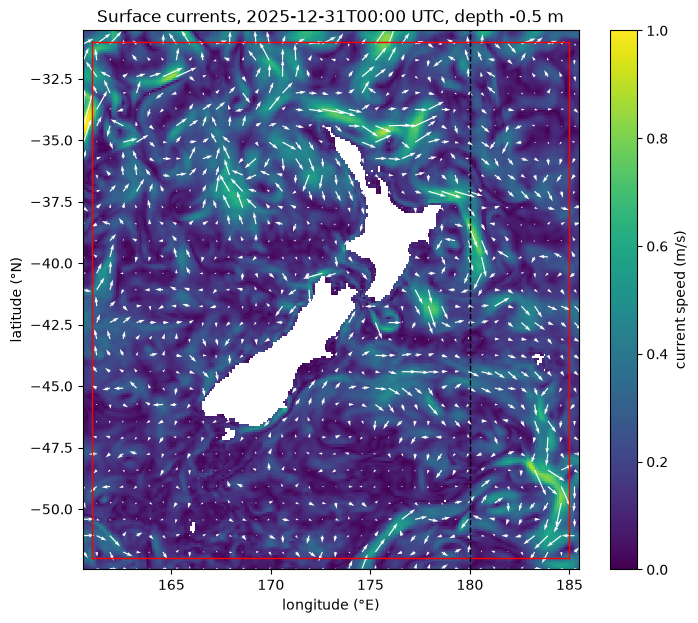

In [35]:
FILE = "/scratch/nn411/clm_test/raw/uo_vo_raw_2025-12-31_2026-01-01.nc"
IT   = 0          # time index: 0-4 (00, 06, 12, 18 UTC, next 00 UTC)
LEVEL = -1        # -1 = surface; 0 = deepest level
# ----------------------

ds = xr.open_dataset(FILE).isel(time=IT, elevation=LEVEL)
g  = xr.open_dataset("/projects/f_omg_1/moa/moana/grid/moana_grid_N50.nc")
glon, glat = g.lon_rho.values % 360, g.lat_rho.values

speed = np.hypot(ds.uo, ds.vo)

plt.figure(figsize=(8, 7))
plt.pcolormesh(ds.longitude, ds.latitude, speed, cmap="viridis", vmin=0, vmax=1, shading="auto")
plt.colorbar(label="current speed (m/s)")
s = 8                                                # every 8th arrow
plt.quiver(ds.longitude[::s], ds.latitude[::s], ds.uo[::s, ::s], ds.vo[::s, ::s], color="w", scale=15)
for e in (np.s_[0, :], np.s_[-1, :], np.s_[:, 0], np.s_[:, -1]):
    plt.plot(glon[e], glat[e], "r", lw=1)             # ROMS grid outline
plt.axvline(180, color="k", ls="--", lw=1)
plt.title(f"Surface currents, {str(ds.time.values)[:16]} UTC, depth {float(ds.elevation):.1f} m")
plt.xlabel("longitude (°E)"); plt.ylabel("latitude (°N)")
plt.savefig(f"{FIGS}/raw_u_v_plot.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
import xroms 

VAR  = "temp"        # u, v, temp, salt
IT   = 4             # record: 0 = 31 Dec 00:00, 4 = 1 Jan 00:00, 20 = 5 Jan 00:00
LAT  = -40.0         # latitude for the vertical section
CMAP = "RdYlBu_r"
# ----------------------

DIR  = "/scratch/nn411/clm_test/roms_ready"
GRID = "/projects/f_omg_1/moa/moana/grid/moana_grid_N50.nc"

clm = xr.open_dataset(f"{DIR}/clm_{VAR}_2025-12-31_2026-01-05.nc", decode_times=False)
g = xr.open_dataset(GRID)
g["zeta"] = xr.zeros_like(g.h)
grid, _ = xroms.roms_dataset(g, Vtransform=2)            # gives the depth of every s-level

pt = {"u": "_u", "v": "_v"}.get(VAR, "")                 # u and v sit on their own grid points
lon  = grid[f"lon_rho{pt}" if pt == "" else f"lon{pt}"] % 360
lat  = grid[f"lat_rho{pt}" if pt == "" else f"lat{pt}"]
z    = grid[f"z_rho{pt}"]
mask = grid[f"mask_rho{pt}" if pt == "" else f"mask{pt}"]
tname = clm[VAR].attrs["time"]
da = clm[VAR].isel({tname: IT}).where(mask.values == 1)  # hide land
print(f"{VAR}, {float(clm[tname][IT]):.2f} days since 2026-01-01")

temp, 0.00 days since 2026-01-01


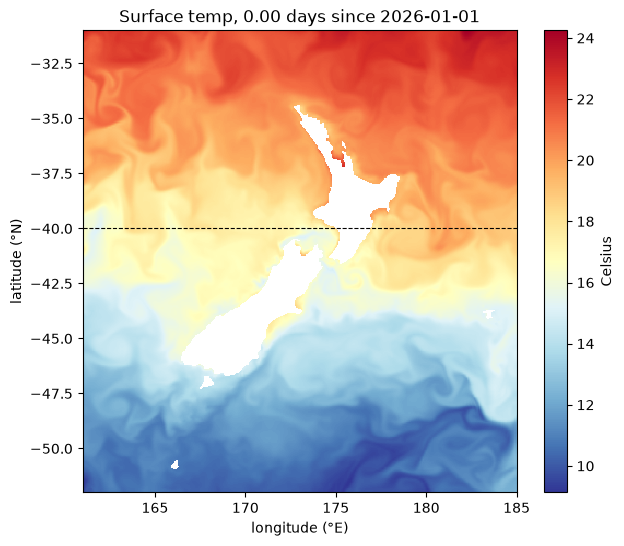

In [5]:
plt.figure(figsize=(7, 6))
plt.pcolormesh(lon, lat, da.isel(s_rho=-1), cmap=CMAP, shading="auto")
plt.colorbar(label=clm[VAR].attrs["units"])
plt.axhline(LAT, color="k", ls="--", lw=0.8)             # where the section is taken
plt.title(f"Surface {VAR}, {float(clm[tname][IT]):.2f} days since 2026-01-01")
plt.xlabel("longitude (°E)"); plt.ylabel("latitude (°N)")
plt.show()

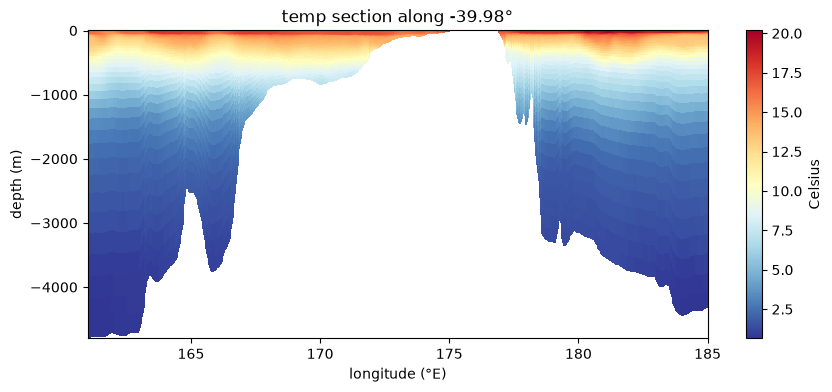

In [6]:
row = int(np.argmin(abs(lat.values[:, 0] - LAT)))        # grid row closest to LAT
plt.figure(figsize=(10, 4))
plt.pcolormesh(np.broadcast_to(lon.values[row], z.values[:, row].shape), z.values[:, row],
               da.values[:, row], cmap=CMAP, shading="auto")
plt.colorbar(label=clm[VAR].attrs["units"])
plt.title(f"{VAR} section along {float(lat.values[row, 0]):.2f}°")
plt.xlabel("longitude (°E)"); plt.ylabel("depth (m)")
plt.show()

In [11]:

VAR  = "salt"        # u, v, temp, salt
IT   = 4             # record: 0 = 31 Dec 00:00, 4 = 1 Jan 00:00, 20 = 5 Jan 00:00
LAT  = -40.0         # latitude for the vertical section
CMAP = "RdYlBu_r"
# ----------------------

DIR  = "/scratch/nn411/clm_test/roms_ready"
GRID = "/projects/f_omg_1/moa/moana/grid/moana_grid_N50.nc"

clm = xr.open_dataset(f"{DIR}/clm_{VAR}_2025-12-31_2026-01-05.nc", decode_times=False)
g = xr.open_dataset(GRID)
g["zeta"] = xr.zeros_like(g.h)
grid, _ = xroms.roms_dataset(g, Vtransform=2)            # gives the depth of every s-level

pt = {"u": "_u", "v": "_v"}.get(VAR, "")                 # u and v sit on their own grid points
lon  = grid[f"lon_rho{pt}" if pt == "" else f"lon{pt}"] % 360
lat  = grid[f"lat_rho{pt}" if pt == "" else f"lat{pt}"]
z    = grid[f"z_rho{pt}"]
mask = grid[f"mask_rho{pt}" if pt == "" else f"mask{pt}"]
tname = clm[VAR].attrs["time"]
da = clm[VAR].isel({tname: IT}).where(mask.values == 1)  # hide land
print(f"{VAR}, {float(clm[tname][IT]):.2f} days since 2026-01-01")

salt, 0.00 days since 2026-01-01


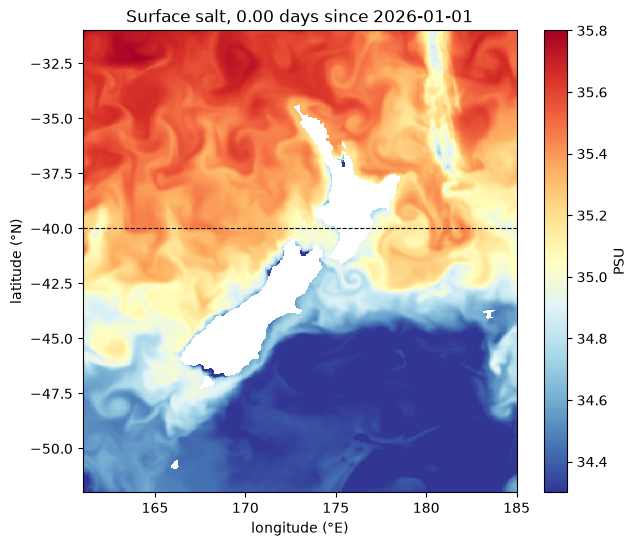

In [12]:
plt.figure(figsize=(7, 6))
plt.pcolormesh(lon, lat, da.isel(s_rho=-1), cmap=CMAP, shading="auto", vmin=34.3, vmax=35.8)
plt.colorbar(label=clm[VAR].attrs["units"])
plt.axhline(LAT, color="k", ls="--", lw=0.8)             # where the section is taken
plt.title(f"Surface {VAR}, {float(clm[tname][IT]):.2f} days since 2026-01-01")
plt.xlabel("longitude (°E)"); plt.ylabel("latitude (°N)")
plt.show()

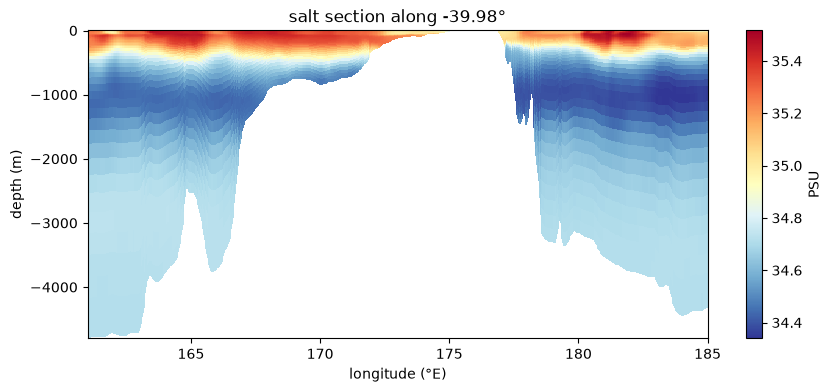

In [13]:
row = int(np.argmin(abs(lat.values[:, 0] - LAT)))        # grid row closest to LAT
plt.figure(figsize=(10, 4))
plt.pcolormesh(np.broadcast_to(lon.values[row], z.values[:, row].shape), z.values[:, row],
               da.values[:, row], cmap=CMAP, shading="auto")
plt.colorbar(label=clm[VAR].attrs["units"])
plt.title(f"{VAR} section along {float(lat.values[row, 0]):.2f}°")
plt.xlabel("longitude (°E)"); plt.ylabel("depth (m)")
plt.show()

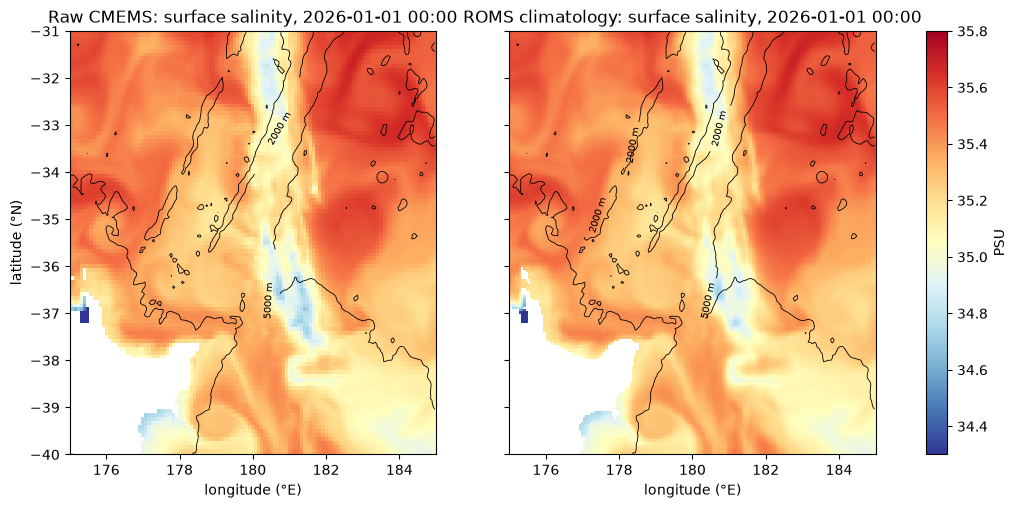

In [14]:
raw = xr.open_dataset("/scratch/nn411/clm_test/raw/so_raw_2026-01-01_2026-01-02.nc").isel(time=0)
raw_s = raw.so.sel(elevation=raw.elevation.max())                 # CMEMS surface, 2026-01-01 00:00

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)
panels = [(axes[0], raw.longitude % 360, raw.latitude, raw_s, "Raw CMEMS"),
          (axes[1], lon, lat, da.isel(s_rho=-1), "ROMS climatology")]
for ax, x, y, field, name in panels:
    pc = ax.pcolormesh(x, y, field, cmap="RdYlBu_r", vmin=34.3, vmax=35.8, shading="auto")
    cs = ax.contour(g.lon_rho % 360, g.lat_rho, g.h, levels=[2000, 5000, 8000], colors="k", linewidths=0.6)
    ax.clabel(cs, fmt="%d m", fontsize=7)
    ax.set_xlim(175, 185); ax.set_ylim(-40, -31)
    ax.set_title(f"{name}: surface salinity, 2026-01-01 00:00")
    ax.set_xlabel("longitude (°E)")
axes[0].set_ylabel("latitude (°N)")
fig.colorbar(pc, ax=axes, label="PSU")
plt.show()

raw time: 2026-01-01T00:00:00.000000000 | clm time: 0.0 days


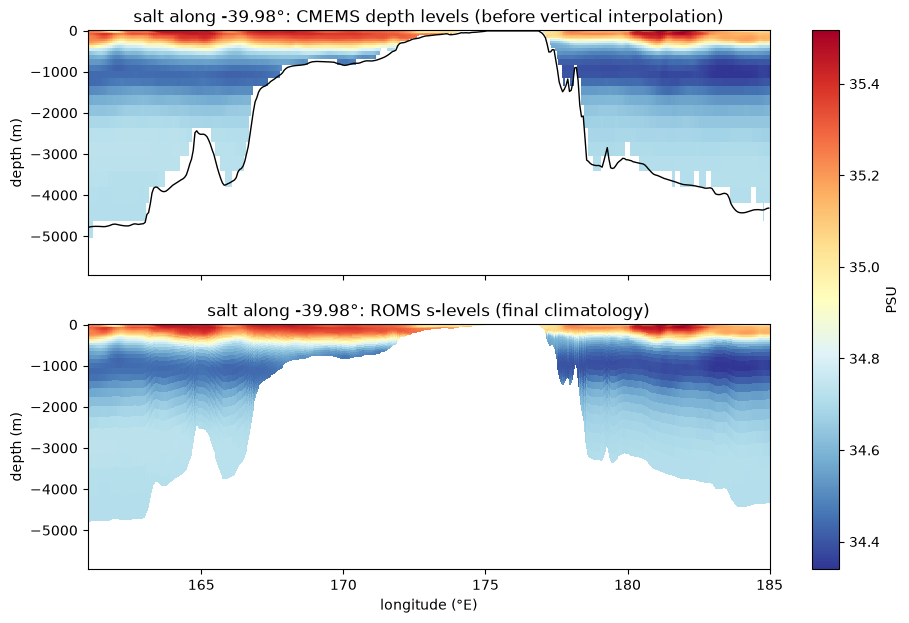

In [15]:
src = {"temp": "thetao", "salt": "so"}[VAR]
raw = xr.open_dataset(f"/scratch/nn411/clm_test/raw/{src}_raw_2026-01-01_2026-01-02.nc")[src].isel(time=0)
raw = raw.assign_coords(longitude=raw.longitude % 360).sortby("longitude")
print("raw time:", raw.time.values, "| clm time:", float(clm[tname][IT]), "days")   # both should be 2026-01-01 00:00

row = int(np.argmin(abs(lat.values[:, 0] - LAT)))
xs = xr.DataArray(lon.values[row], dims="x")
ys = xr.DataArray(lat.values[row], dims="x")
before = raw.interp(longitude=xs, latitude=ys)            # horizontal only: CMEMS depth levels
after = da.values[:, row]                                 # horizontal + vertical: ROMS s-levels

vmin, vmax = float(np.nanmin(after)), float(np.nanmax(after))
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, sharey=True)
axes[0].pcolormesh(lon.values[row], raw.elevation, before, cmap=CMAP, vmin=vmin, vmax=vmax, shading="auto")
axes[0].plot(lon.values[row], -g.h.values[row], "k", lw=1)                     # ROMS seafloor
axes[0].set_title(f"{VAR} along {float(lat.values[row, 0]):.2f}°: CMEMS depth levels (before vertical interpolation)")
pc = axes[1].pcolormesh(np.broadcast_to(lon.values[row], z.values[:, row].shape), z.values[:, row], after,
                        cmap=CMAP, vmin=vmin, vmax=vmax, shading="auto")
axes[1].set_title(f"{VAR} along {float(lat.values[row, 0]):.2f}°: ROMS s-levels (final climatology)")
for ax in axes:
    ax.set_ylabel("depth (m)")
axes[1].set_xlabel("longitude (°E)")
fig.colorbar(pc, ax=axes, label=clm[VAR].attrs["units"])
plt.show()

IC: ('s_rho', 'eta_rho', 'xi_rho') (50, 467, 397) | CLM: (50, 467, 397)
max |clm - ic| over all ocean points and levels: 6.75e-06 PSU


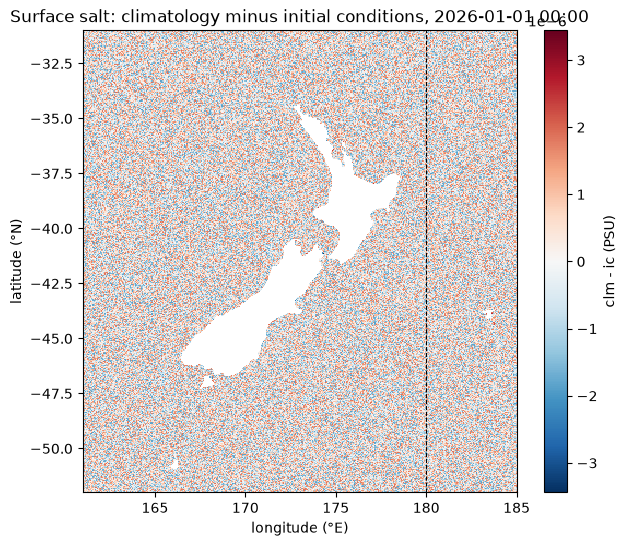

In [17]:
ic = xr.open_dataset(f"/projects/f_omg_1/moa/moana/oceanum_input/initial_cond/roms_ready/ic_{VAR}_2026-01-01.nc")[VAR].squeeze(drop=True)
clm0 = clm[VAR].isel({tname: 4})                          # 2026-01-01 00:00
print("IC:", ic.dims, ic.shape, "| CLM:", clm0.shape)

ocean_mask = mask.values == 1
diff = np.where(ocean_mask, clm0.values - ic.values, np.nan)
print(f"max |clm - ic| over all ocean points and levels: {np.nanmax(abs(diff)):.2e} {clm[VAR].attrs['units']}")

lim = max(np.nanmax(abs(diff[-1])), 1e-6)
plt.figure(figsize=(7, 6))
plt.pcolormesh(lon, lat, diff[-1], cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
plt.colorbar(label=f"clm - ic ({clm[VAR].attrs['units']})")
plt.axvline(180, color="k", ls="--", lw=0.8)
plt.title(f"Surface {VAR}: climatology minus initial conditions, 2026-01-01 00:00")
plt.xlabel("longitude (°E)"); plt.ylabel("latitude (°N)")
plt.show()

In [20]:
VAR  = "u"        # u, v, temp, salt
IT   = 4             # record: 0 = 31 Dec 00:00, 4 = 1 Jan 00:00, 20 = 5 Jan 00:00
LAT  = -40.0         # latitude for the vertical section
CMAP = "RdYlBu_r"
# ----------------------

DIR  = "/scratch/nn411/clm_test/roms_ready"
GRID = "/projects/f_omg_1/moa/moana/grid/moana_grid_N50.nc"

clm = xr.open_dataset(f"{DIR}/clm_{VAR}_2025-12-31_2026-01-05.nc", decode_times=False)
g = xr.open_dataset(GRID)
g["zeta"] = xr.zeros_like(g.h)
grid, _ = xroms.roms_dataset(g, Vtransform=2)            # gives the depth of every s-level

pt = {"u": "_u", "v": "_v"}.get(VAR, "")                 # u and v sit on their own grid points
lon  = grid[f"lon_rho{pt}" if pt == "" else f"lon{pt}"] % 360
lat  = grid[f"lat_rho{pt}" if pt == "" else f"lat{pt}"]
z    = grid[f"z_rho{pt}"]
mask = grid[f"mask_rho{pt}" if pt == "" else f"mask{pt}"]
tname = clm[VAR].attrs["time"]
da = clm[VAR].isel({tname: IT}).where(mask.values == 1)  # hide land
print(f"{VAR}, {float(clm[tname][IT]):.2f} days since 2026-01-01")

u, 0.00 days since 2026-01-01


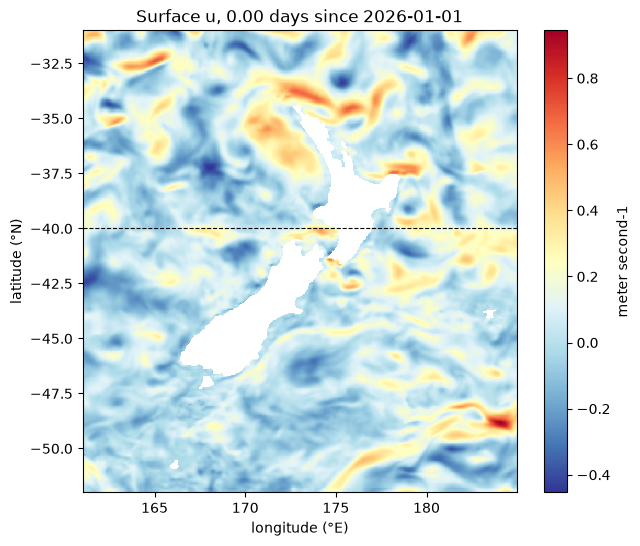

In [22]:
plt.figure(figsize=(7, 6))
plt.pcolormesh(lon, lat, da.isel(s_rho=-1), cmap=CMAP, shading="auto")
plt.colorbar(label=clm[VAR].attrs["units"])
plt.axhline(LAT, color="k", ls="--", lw=0.8)             # where the section is taken
plt.title(f"Surface {VAR}, {float(clm[tname][IT]):.2f} days since 2026-01-01")
plt.xlabel("longitude (°E)"); plt.ylabel("latitude (°N)")
plt.show()

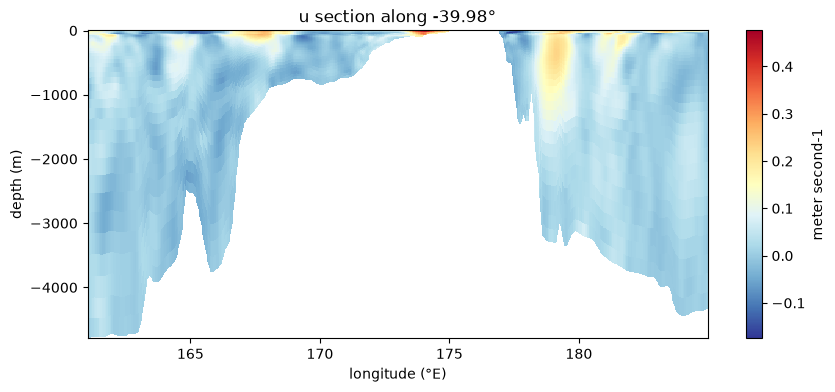

In [23]:
row = int(np.argmin(abs(lat.values[:, 0] - LAT)))        # grid row closest to LAT
plt.figure(figsize=(10, 4))
plt.pcolormesh(np.broadcast_to(lon.values[row], z.values[:, row].shape), z.values[:, row],
               da.values[:, row], cmap=CMAP, shading="auto")
plt.colorbar(label=clm[VAR].attrs["units"])
plt.title(f"{VAR} section along {float(lat.values[row, 0]):.2f}°")
plt.xlabel("longitude (°E)"); plt.ylabel("depth (m)")
plt.show()

In [24]:
VAR  = "v"        # u, v, temp, salt
IT   = 4             # record: 0 = 31 Dec 00:00, 4 = 1 Jan 00:00, 20 = 5 Jan 00:00
LAT  = -40.0         # latitude for the vertical section
CMAP = "RdYlBu_r"
# ----------------------

DIR  = "/scratch/nn411/clm_test/roms_ready"
GRID = "/projects/f_omg_1/moa/moana/grid/moana_grid_N50.nc"

clm = xr.open_dataset(f"{DIR}/clm_{VAR}_2025-12-31_2026-01-05.nc", decode_times=False)
g = xr.open_dataset(GRID)
g["zeta"] = xr.zeros_like(g.h)
grid, _ = xroms.roms_dataset(g, Vtransform=2)            # gives the depth of every s-level

pt = {"u": "_u", "v": "_v"}.get(VAR, "")                 # u and v sit on their own grid points
lon  = grid[f"lon_rho{pt}" if pt == "" else f"lon{pt}"] % 360
lat  = grid[f"lat_rho{pt}" if pt == "" else f"lat{pt}"]
z    = grid[f"z_rho{pt}"]
mask = grid[f"mask_rho{pt}" if pt == "" else f"mask{pt}"]
tname = clm[VAR].attrs["time"]
da = clm[VAR].isel({tname: IT}).where(mask.values == 1)  # hide land
print(f"{VAR}, {float(clm[tname][IT]):.2f} days since 2026-01-01")

v, 0.00 days since 2026-01-01


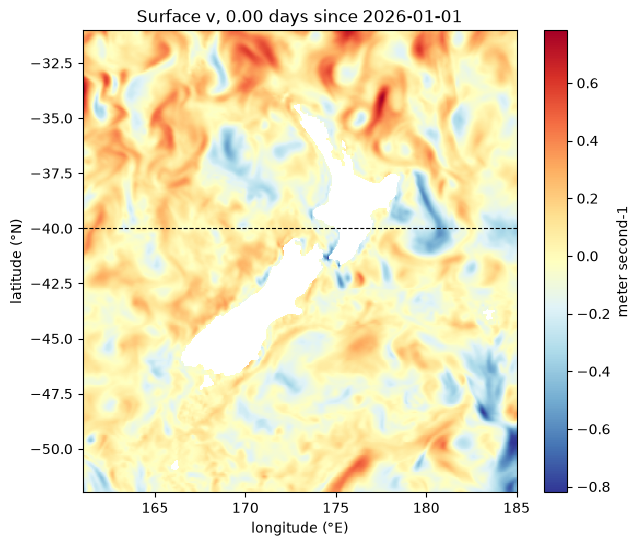

In [25]:
plt.figure(figsize=(7, 6))
plt.pcolormesh(lon, lat, da.isel(s_rho=-1), cmap=CMAP, shading="auto")
plt.colorbar(label=clm[VAR].attrs["units"])
plt.axhline(LAT, color="k", ls="--", lw=0.8)             # where the section is taken
plt.title(f"Surface {VAR}, {float(clm[tname][IT]):.2f} days since 2026-01-01")
plt.xlabel("longitude (°E)"); plt.ylabel("latitude (°N)")
plt.show()

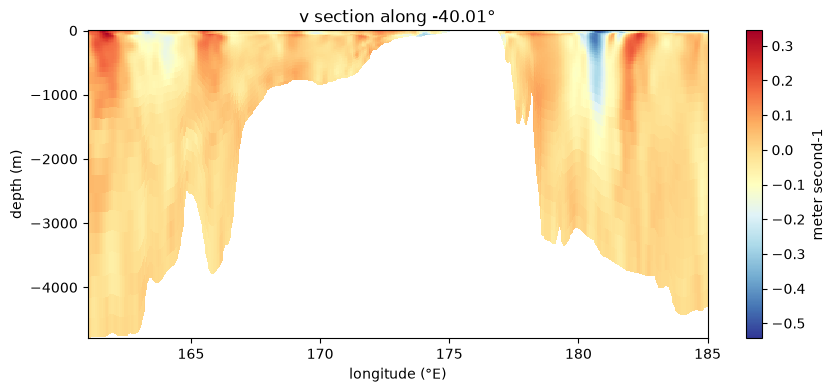

In [26]:
row = int(np.argmin(abs(lat.values[:, 0] - LAT)))        # grid row closest to LAT
plt.figure(figsize=(10, 4))
plt.pcolormesh(np.broadcast_to(lon.values[row], z.values[:, row].shape), z.values[:, row],
               da.values[:, row], cmap=CMAP, shading="auto")
plt.colorbar(label=clm[VAR].attrs["units"])
plt.title(f"{VAR} section along {float(lat.values[row, 0]):.2f}°")
plt.xlabel("longitude (°E)"); plt.ylabel("depth (m)")
plt.show()

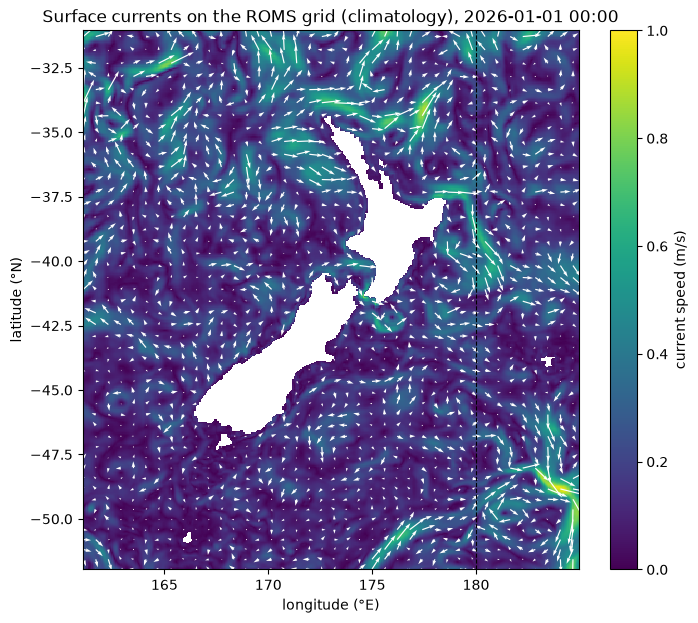

In [27]:
DIR = "/scratch/nn411/clm_test/roms_ready"
IT_UV = 4                                              # 2026-01-01 00:00

u = xr.open_dataset(f"{DIR}/clm_u_2025-12-31_2026-01-05.nc").u.isel(v3d_time=IT_UV, s_rho=-1).values
v = xr.open_dataset(f"{DIR}/clm_v_2025-12-31_2026-01-05.nc").v.isel(v3d_time=IT_UV, s_rho=-1).values

# average onto interior rho points (cell centres)
u_c = 0.5 * (u[1:-1, :-1] + u[1:-1, 1:])               # (eta_rho-2, xi_rho-2)
v_c = 0.5 * (v[:-1, 1:-1] + v[1:, 1:-1])
lon_c = g.lon_rho.values[1:-1, 1:-1] % 360
lat_c = g.lat_rho.values[1:-1, 1:-1]
ocean_c = g.mask_rho.values[1:-1, 1:-1] == 1
speed = np.where(ocean_c, np.hypot(u_c, v_c), np.nan)

plt.figure(figsize=(8, 7))
plt.pcolormesh(lon_c, lat_c, speed, cmap="viridis", vmin=0, vmax=1, shading="auto")
plt.colorbar(label="current speed (m/s)")
s = 10                                                 # every 10th arrow
plt.quiver(lon_c[::s, ::s], lat_c[::s, ::s], np.where(ocean_c, u_c, np.nan)[::s, ::s],
           np.where(ocean_c, v_c, np.nan)[::s, ::s], color="w", scale=15)
plt.axvline(180, color="k", ls="--", lw=0.8)
plt.title("Surface currents on the ROMS grid (climatology), 2026-01-01 00:00")
plt.xlabel("longitude (°E)"); plt.ylabel("latitude (°N)")
plt.show()

point: 182.01°E, -39.98°, bottom 3748 m, deep level at -1029 m


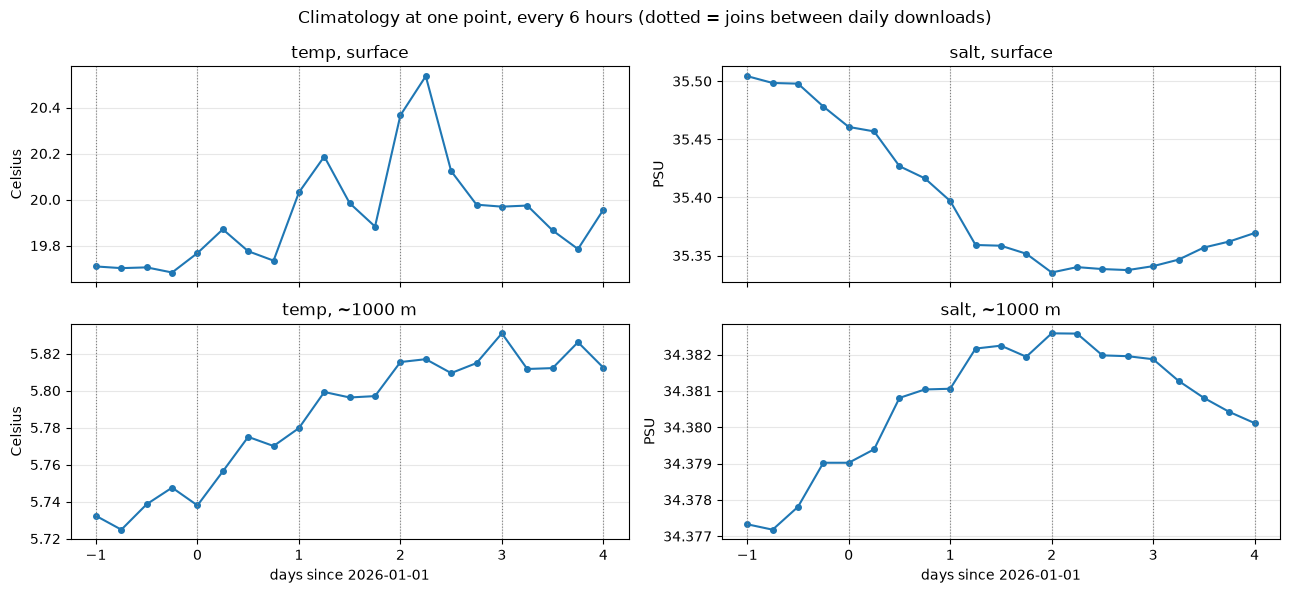

In [31]:
PLON, PLAT, DEPTH = 182.0, -40.0, -1000.0             # deep point east of NZ; second depth (m)
DIR = "/scratch/nn411/clm_test/roms_ready"

grd = xroms.roms_dataset(g, Vtransform=2)[0]
j, i = np.unravel_index(np.argmin((g.lon_rho.values % 360 - PLON) ** 2 + (g.lat_rho.values - PLAT) ** 2),
                        g.lon_rho.shape)
k_deep = int(np.argmin(abs(grd.z_rho.values[:, j, i] - DEPTH)))
print(f"point: {g.lon_rho.values[j, i] % 360:.2f}°E, {g.lat_rho.values[j, i]:.2f}°, "
      f"bottom {g.h.values[j, i]:.0f} m, deep level at {grd.z_rho.values[k_deep, j, i]:.0f} m")

fig, axes = plt.subplots(2, 2, figsize=(13, 6), sharex=True)
for col, var in enumerate(["temp", "salt"]):
    ds = xr.open_dataset(f"{DIR}/clm_{var}_2025-12-31_2026-01-05.nc", decode_times=False)
    t = ds[f"{var}_time"].values
    if np.issubdtype(t.dtype, np.datetime64):            # just in case: convert dates to days
        t = (t - np.datetime64("2026-01-01")) / np.timedelta64(1, "D")
    for row, (k, name) in enumerate([(-1, "surface"), (k_deep, f"~{-DEPTH:.0f} m")]):
        ax = axes[row, col]
        ax.plot(t, ds[var].values[:, k, j, i], "o-", ms=4)
        for d in range(-1, 5):
            ax.axvline(d, color="gray", ls=":", lw=0.8)    # joins between daily files
        ax.set_title(f"{var}, {name}")
        ax.set_ylabel(ds[var].attrs["units"])
        ax.grid(alpha=0.3)
for ax in axes[-1]:
    ax.set_xlabel("days since 2026-01-01")
fig.suptitle("Climatology at one point, every 6 hours (dotted = joins between daily downloads)")
plt.tight_layout()
plt.show()

raw time: 2026-01-01T00:00 | climatology time: 0.0 days


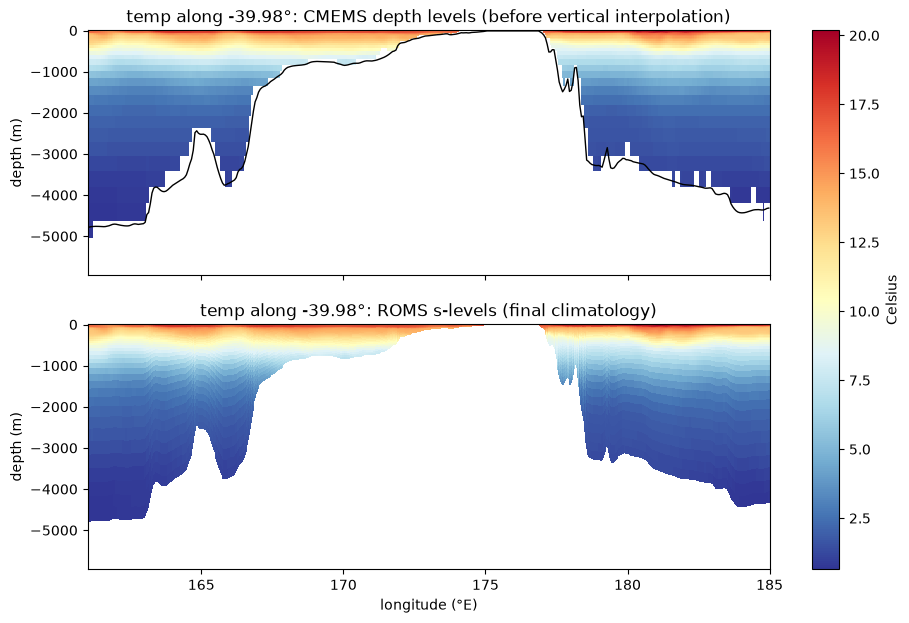

In [33]:

VAR = "temp"           # "salt" or "temp"
LAT = -40.0            # latitude of the section
# ----------------------

RAW  = "/scratch/nn411/clm_test/raw"
IT   = 4               # climatology record for 2026-01-01 00:00
CMAP = "RdYlBu_r"

# ROMS grid and the depth of every s-level
g = xr.open_dataset(GRID)
g["zeta"] = xr.zeros_like(g.h)
grid, _ = xroms.roms_dataset(g, Vtransform=2)
lon, lat, z = grid.lon_rho % 360, grid.lat_rho, grid.z_rho
ocean = grid.mask_rho.values == 1

# AFTER: final climatology on ROMS s-levels
clm = xr.open_dataset(f"{DIR}/clm_{VAR}_2025-12-31_2026-01-05.nc", decode_times=False)
after_full = np.where(ocean, clm[VAR].values[IT], np.nan)        # (s_rho, eta, xi)

# BEFORE: raw CMEMS, same time, interpolated horizontally onto the ROMS section points only
src = {"temp": "thetao", "salt": "so"}[VAR]
raw = xr.open_dataset(f"{RAW}/{src}_raw_2026-01-01_2026-01-02.nc")[src].isel(time=0)
raw = raw.assign_coords(longitude=raw.longitude % 360).sortby("longitude")
print("raw time:", str(raw.time.values)[:16], "| climatology time:", float(clm[f"{VAR}_time"][IT]), "days")

row = int(np.argmin(abs(lat.values[:, 0] - LAT)))
x = lon.values[row]
before = raw.interp(longitude=xr.DataArray(x, dims="x"), latitude=xr.DataArray(lat.values[row], dims="x"))
after = after_full[:, row]

# plot both with the same colour range
vmin, vmax = np.nanmin(after), np.nanmax(after)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, sharey=True)
axes[0].pcolormesh(x, raw.elevation, before, cmap=CMAP, vmin=vmin, vmax=vmax, shading="auto")
axes[0].plot(x, -g.h.values[row], "k", lw=1)
axes[0].set_title(f"{VAR} along {lat.values[row, 0]:.2f}°: CMEMS depth levels (before vertical interpolation)")
pc = axes[1].pcolormesh(np.broadcast_to(x, z.values[:, row].shape), z.values[:, row], after,
                        cmap=CMAP, vmin=vmin, vmax=vmax, shading="auto")
axes[1].set_title(f"{VAR} along {lat.values[row, 0]:.2f}°: ROMS s-levels (final climatology)")
for ax in axes:
    ax.set_ylabel("depth (m)")
axes[1].set_xlabel("longitude (°E)")
fig.colorbar(pc, ax=axes, label=clm[VAR].attrs["units"])
plt.show()